In [1]:

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:

import pandas as pd

# /content/drive/MyDrive/Copy of df_clean.pkl
# /content/drive/MyDrive/EE/df_clean.pkl
df = pd.read_pickle('/content/drive/MyDrive/Copy of df_clean.pkl')
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(df, test_size = 0.2, random_state = 42, shuffle = True)

# Model 1


In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import pandas as pd


class ChessFinalBoardDatasetWithELO(Dataset):
    def __init__(self, dataframe):
        self.df = dataframe

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        game_tensor = self.df.iloc[idx]['game_tensor']
        label = int(self.df.iloc[idx]['result'])
        final_board = game_tensor[-1]

        white_elo = self.df.iloc[idx]['white_elo']
        black_elo = self.df.iloc[idx]['black_elo']
        elo_diff = torch.tensor([(white_elo - black_elo) / 1000.0], dtype = torch.float32)

        return final_board.float(), elo_diff, torch.tensor(label, dtype = torch.long)

In [4]:
class ChessCNNWithELO(nn.Module):
    def __init__(self):
        super(ChessCNNWithELO, self).__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(12, 32, kernel_size = 3, padding = 1),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size = 3, padding = 1),
            nn.ReLU(),
            nn.Flatten()
        )
        self.mlp = nn.Sequential(
            nn.Linear(64 * 8 * 8 + 1, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 2)
        )

    def forward(self, board, elo_diff):
        features = self.cnn(board)
        combined = torch.cat([features, elo_diff], dim = 1)
        return self.mlp(combined)



dataset_train = ChessFinalBoardDatasetWithELO(train_df)
train_loader = DataLoader(dataset_train, batch_size = 8, shuffle=True, num_workers = 0)
dataset_test = ChessFinalBoardDatasetWithELO(test_df)
test_loader = DataLoader(dataset_test, batch_size = 8, shuffle=False, num_workers = 0)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = ChessCNNWithELO().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr = 1e-4)

In [5]:
# Train

train_losses = []
test_accuracies = []


num_epochs = 20
for epoch in range(num_epochs):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for boards, elo_diffs, labels in train_loader:
        boards = boards.to(device)
        elo_diffs = elo_diffs.to(device)
        labels = labels.to(device)

        outputs = model(boards, elo_diffs)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        _, predicted = torch.max(outputs, dim=1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    acc = 100 * correct / total
    total = 0
    correct = 0
    # Evaluation
    model.eval()
    with torch.no_grad():
      for boards, elo_diffs, labels in test_loader:
          boards = boards.to(device)
          elo_diffs = elo_diffs.to(device)
          labels = labels.to(device)
          outputs = model(boards, elo_diffs)
          _, predicted = torch.max(outputs, dim=1)
          correct += (predicted == labels).sum().item()
          total += labels.size(0)
    test_acc = 100 * correct / total

    train_losses.append(total_loss)
    test_accuracies.append(test_acc)

    if(test_acc >= 64.05):
      torch.save(model, f"model_at_{test_acc:.2f}.pt")
    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {total_loss:.4f}, Accuracy: {test_acc:.2f}%")

Epoch [1/20], Loss: 6322.3749, Accuracy: 64.05%
Epoch [2/20], Loss: 6216.5732, Accuracy: 63.97%
Epoch [3/20], Loss: 6196.0113, Accuracy: 63.98%
Epoch [4/20], Loss: 6167.0108, Accuracy: 63.94%
Epoch [5/20], Loss: 6131.7514, Accuracy: 63.48%
Epoch [6/20], Loss: 6084.7047, Accuracy: 63.37%
Epoch [7/20], Loss: 6025.0676, Accuracy: 63.32%
Epoch [8/20], Loss: 5952.6719, Accuracy: 62.96%
Epoch [9/20], Loss: 5866.5842, Accuracy: 62.70%
Epoch [10/20], Loss: 5753.2750, Accuracy: 62.18%
Epoch [11/20], Loss: 5614.5885, Accuracy: 61.87%
Epoch [12/20], Loss: 5450.8719, Accuracy: 61.46%
Epoch [13/20], Loss: 5249.3750, Accuracy: 61.06%
Epoch [14/20], Loss: 5020.8256, Accuracy: 60.89%
Epoch [15/20], Loss: 4747.4518, Accuracy: 59.27%
Epoch [16/20], Loss: 4461.8495, Accuracy: 58.83%
Epoch [17/20], Loss: 4162.4660, Accuracy: 58.74%
Epoch [18/20], Loss: 3841.1558, Accuracy: 58.82%
Epoch [19/20], Loss: 3575.5386, Accuracy: 59.17%
Epoch [20/20], Loss: 3302.0359, Accuracy: 57.80%


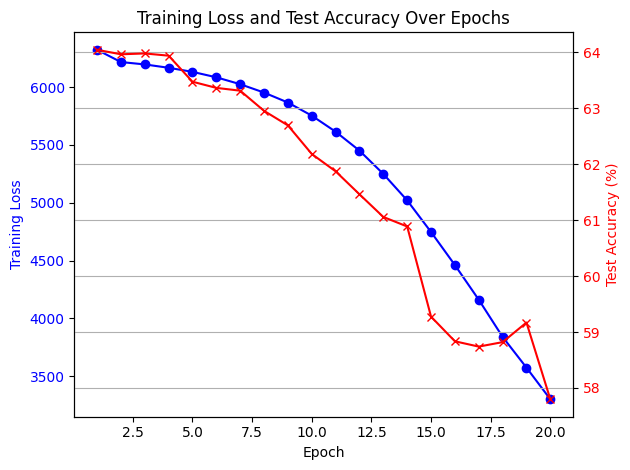

In [6]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots()

# Plot training loss
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Training Loss', color='blue')
ax1.plot(range(1, num_epochs + 1), train_losses, color='blue', marker='o', label='Training Loss')
ax1.tick_params(axis='y', labelcolor='blue')

# Plot test accuracy
ax2 = ax1.twinx()
ax2.set_ylabel('Test Accuracy (%)', color='red')
ax2.plot(range(1, num_epochs + 1), test_accuracies, color='red', marker='x', label='Test Accuracy')
ax2.tick_params(axis='y', labelcolor='red')

plt.title('Training Loss and Test Accuracy Over Epochs')
plt.grid(True)
plt.tight_layout()
plt.show()


# Model 2

In [7]:
import torch
import torch.nn as nn

class ChessCNNRNNModel(nn.Module):
    def __init__(self):
        super(ChessCNNRNNModel, self).__init__()

        self.cnn = nn.Sequential(
            nn.Conv2d(12, 32, kernel_size = 3, padding = 1),
            nn.GELU(),
            nn.Conv2d(32, 64, kernel_size = 3, padding = 1),
            nn.GELU(),
            nn.Flatten()
        )

        self.cnn_output_size = 64 * 8 * 8
        self.rnn_input_size = self.cnn_output_size + 1

        self.rnn = nn.GRU(input_size = self.rnn_input_size, hidden_size = 256, batch_first = True)

        self.mlp = nn.Sequential(
            nn.Linear(256, 128),
            nn.GELU(),
            nn.Linear(128, 2)
        )

    def forward(self, board_tensor, evals):
        """
        board_tensor: (B, T, 12, 8, 8)
        evals: (B, T, 1)
        """
        B, T, C, H, W = board_tensor.shape
        boards_reshaped = board_tensor.view(B * T, C, H, W)
        cnn_features = self.cnn(boards_reshaped).view(B, T, -1)
        combined_features = torch.cat([cnn_features, evals], dim = -1)
        rnn_out, _ = self.rnn(combined_features)
        final_feature = rnn_out[:, -1, :]
        return self.mlp(final_feature)


In [8]:
from torch.utils.data import Dataset
import torch

class ChessGameDataset(Dataset):
    def __init__(self, dataframe):
        self.df = dataframe

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        game_tensor = self.df.iloc[idx]['game_tensor']
        eval_tensor = self.df.iloc[idx]['eval_tensor']
        label = int(self.df.iloc[idx]['result'])


        if eval_tensor.ndim == 1:
            eval_tensor = eval_tensor.unsqueeze(-1)

        return game_tensor.float(), eval_tensor.float(), torch.tensor(label, dtype = torch.long)


In [9]:
chess_dataset = ChessGameDataset(train_df)
validation = ChessGameDataset(test_df)


In [10]:
from torch.nn.utils.rnn import pad_sequence

def pad_collate(batch):
    """
    Pads game_tensor and eval_tensor along the time dimension.
    """
    game_tensors, eval_tensors, labels = zip(*batch)


    padded_game = pad_sequence(game_tensors, batch_first = True)
    padded_eval = pad_sequence(eval_tensors, batch_first = True)

    labels = torch.stack(labels)
    return padded_game, padded_eval, labels


In [11]:
from torch.utils.data import DataLoader
train_loader = DataLoader(chess_dataset, batch_size = 1024, shuffle = True, collate_fn = pad_collate)
test_loader = DataLoader(validation, batch_size = 1024, shuffle = True, collate_fn = pad_collate)

train

In [12]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = ChessCNNRNNModel().to(device)
import torch.nn as nn
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr = 8e-4, weight_decay = 1e-5)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=0.5, patience=3, verbose=True
)
all_eval_tensors = []

for _, eval_tensor, _ in train_loader:
    all_eval_tensors.append(eval_tensor)

all_eval_tensors = torch.cat(all_eval_tensors, dim = 0)

eval_mean = all_eval_tensors.mean()
eval_std = all_eval_tensors.std()
eval_mean = eval_mean.to(device)
eval_std = eval_std.to(device)

all_eval_tensors = []

for _, eval_tensor, _ in test_loader:
    all_eval_tensors.append(eval_tensor)

all_eval_tensors = torch.cat(all_eval_tensors, dim = 0)

eval_mean_test = all_eval_tensors.mean()
eval_std_test = all_eval_tensors.std()
eval_mean_test = eval_mean.to(device)
eval_std_test = eval_std.to(device)


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


In [13]:
train_losses = []
train_accuracies = []
test_accuracies = []


num_epochs = 40
for epoch in range(num_epochs):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for board_tensor, eval_tensor, labels in train_loader:
        board_tensor = board_tensor.to(device)
        eval_tensor = eval_tensor.to(device)
        eval_tensor = (eval_tensor - eval_mean) / eval_std
        labels = labels.to(device)

        outputs = model(board_tensor, eval_tensor)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        _, predicted = torch.max(outputs, dim=1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    train_accuracy = 100 * correct / total

    # Evaluation
    model.eval()
    test_correct = 0
    with torch.no_grad():
        for board_tensor, eval_tensor, labels in test_loader:
            board_tensor = board_tensor.to(device)
            eval_tensor = eval_tensor.to(device)
            eval_tensor = (eval_tensor - eval_mean_test) / eval_std_test
            labels = labels.to(device)
            outputs = model(board_tensor, eval_tensor)
            _, predicted = torch.max(outputs, dim=1)
            test_correct += (predicted == labels).sum().item()

    test_accuracy = 100 * test_correct / len(test_loader.dataset)
    scheduler.step(test_accuracy)

    train_losses.append(total_loss)
    train_accuracies.append(train_accuracy)
    test_accuracies.append(test_accuracy)

    if(test_accuracy >= 57.9):
      torch.save(model, f"model_at_{test_accuracy:.2f}.pt")
    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {total_loss:.4f}, "
          f"Train Accuracy: {train_accuracy:.2f}%, Test Accuracy: {test_accuracy:.2f}%")


Epoch [1/40], Loss: 53.0536, Train Accuracy: 55.93%, Test Accuracy: 56.62%
Epoch [2/40], Loss: 52.8746, Train Accuracy: 56.71%, Test Accuracy: 56.64%
Epoch [3/40], Loss: 52.7465, Train Accuracy: 56.98%, Test Accuracy: 56.92%
Epoch [4/40], Loss: 52.6571, Train Accuracy: 56.99%, Test Accuracy: 57.09%
Epoch [5/40], Loss: 52.5802, Train Accuracy: 57.14%, Test Accuracy: 57.39%
Epoch [6/40], Loss: 52.4767, Train Accuracy: 57.42%, Test Accuracy: 57.32%
Epoch [7/40], Loss: 52.4063, Train Accuracy: 57.47%, Test Accuracy: 57.04%
Epoch [8/40], Loss: 52.3669, Train Accuracy: 57.57%, Test Accuracy: 57.81%
Epoch [9/40], Loss: 52.3025, Train Accuracy: 57.54%, Test Accuracy: 57.63%
Epoch [10/40], Loss: 52.2701, Train Accuracy: 57.66%, Test Accuracy: 57.13%
Epoch [11/40], Loss: 52.2476, Train Accuracy: 57.43%, Test Accuracy: 57.22%
Epoch [12/40], Loss: 52.1642, Train Accuracy: 57.75%, Test Accuracy: 57.31%
Epoch [13/40], Loss: 51.9706, Train Accuracy: 58.06%, Test Accuracy: 57.27%
Epoch [14/40], Loss: 

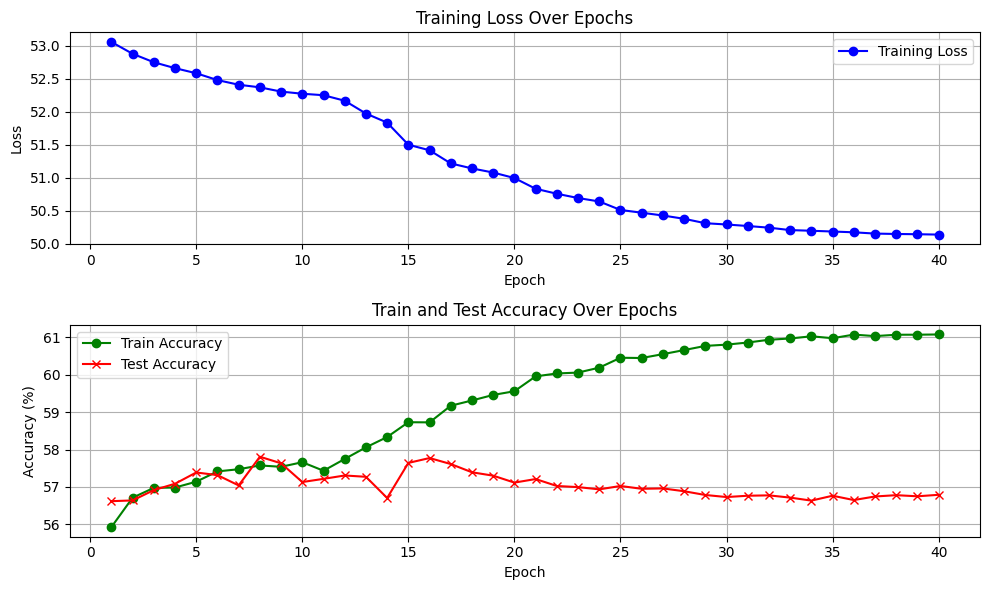

In [14]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(10, 6))

# Plot training loss
plt.subplot(2, 1, 1)
plt.plot(epochs, train_losses, 'b-o', label='Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss Over Epochs')
plt.grid(True)
plt.legend()

# Plot accuracy
plt.subplot(2, 1, 2)
plt.plot(epochs, train_accuracies, 'g-o', label='Train Accuracy')
plt.plot(epochs, test_accuracies, 'r-x', label='Test Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('Train and Test Accuracy Over Epochs')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()


In [15]:
%%shell
jupyter nbconvert --to html /content/Yurui_Plot_EE244_CHESS_PROJECT.ipynb

[NbConvertApp] Converting notebook /content/Yurui_Plot_EE244_CHESS_PROJECT.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 2 image(s).
[NbConvertApp] Writing 486220 bytes to /content/Yurui_Plot_EE244_CHESS_PROJECT.html
